# Recompra a 60 días - The Look eCommerce
**Tais Arrunátegui Matos** · caso práctico Machine Learning Engineer

La pregunta es: de los clientes que acaban de hacer su primera compra, ¿quiénes van a volver a comprar en los siguientes 60 días? Cuento como recompra una **orden nueva**, no otro ítem dentro de la misma orden.

El notebook va en este orden: reviso la calidad de las tablas, armo la tabla base en BigQuery, miro un poco los datos, comparo tres modelos y al final genero predicciones para los clientes que todavía están dentro de su ventana de 60 días. Todo sale de la celda `CONFIG`; si se cambia la fecha de corte o la ventana, lo demás se recalcula solo.

Para correrlo en Colab: *Entorno de ejecución → Ejecutar todo* (pide iniciar sesión con una cuenta que tenga acceso al proyecto). En local, `Restart & Run All` con las dependencias de `requirements.txt`.

## 0. Configuración

In [1]:
import datetime as dt

CONFIG = {
    "PROYECTO":          "bussiness-case-tyc",
    "DATASET_ORIGEN":    "bussiness_case_ecommerce",
    "DATASET_DESTINO":   "tais_arrunategui",   # mi dataset: aqui van la tabla base y las predicciones

    # la ultima orden es del 14/02/2025, corto el 15 (exclusivo) para usar toda la historia.
    # con None toma el 1er dia del mes de la ultima orden
    "FECHA_CORTE":       dt.date(2025, 2, 15),
    "VENTANA_DIAS":      60,
    "ESTADOS_EXCLUIDOS": ["Cancelled"],        # Returned si cuenta, ver seccion 1

    "FRACCION_TEST":     0.20,   # el 20% mas reciente queda para evaluar
    "CAPACIDAD_CAMPANA": 0.20,   # supuesto mio: marketing puede contactar a 1 de cada 5
    "SEMILLA":           42,

    "GUARDAR_EN_BQ":     True,
    "REPO_URL":          "https://github.com/TaisAM3103/recompra-60d-tais-arrunategui.git",
}
CONFIG

{'PROYECTO': 'bussiness-case-tyc',
 'DATASET_ORIGEN': 'bussiness_case_ecommerce',
 'DATASET_DESTINO': 'tais_arrunategui',
 'FECHA_CORTE': datetime.date(2025, 2, 15),
 'VENTANA_DIAS': 60,
 'ESTADOS_EXCLUIDOS': ['Cancelled'],
 'FRACCION_TEST': 0.2,
 'CAPACIDAD_CAMPANA': 0.2,
 'SEMILLA': 42,
 'GUARDAR_EN_BQ': True,
 'REPO_URL': 'https://github.com/TaisAM3103/recompra-60d-tais-arrunategui.git'}

In [2]:
import json, math, os, subprocess, sys, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 180)

# en Colab: login y clono el repo (los .sql viven ahi)
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import auth
    auth.authenticate_user()
    if not Path("recompra-60d-tais-arrunategui").exists():
        subprocess.run(["git", "clone", CONFIG["REPO_URL"]], check=True)
    os.chdir("recompra-60d-tais-arrunategui")

# funciona si se abre desde notebooks/ o desde la raiz
RAIZ = Path.cwd() if (Path.cwd() / "sql").exists() else Path.cwd().parent
DIR_SQL, DIR_SALIDAS, DIR_MODELOS = RAIZ / "sql", RAIZ / "outputs", RAIZ / "models"
DIR_FIGURAS = DIR_SALIDAS / "figuras"
for d in (DIR_SALIDAS, DIR_MODELOS, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
print("Raíz del repo:", RAIZ)

Raíz del repo: /content/recompra-60d-tais-arrunategui


### Conexión a BigQuery
Dejé todo lo de BigQuery en esta celda. Las consultas reciben parámetros (`@fecha_corte`, `@ventana_dias`, `@estados_excluidos`) en lugar de armar el SQL concatenando strings.

Las escrituras se pueden repetir sin duplicar nada: la tabla base se reemplaza completa y las predicciones solo en la partición de su fecha de corte.

In [3]:
from google.api_core.exceptions import NotFound
from google.cloud import bigquery

client = bigquery.Client(project=CONFIG["PROYECTO"])


def _parametro(nombre, valor):
    # valor de python -> parametro tipado de BQ
    if isinstance(valor, (list, tuple)):
        return bigquery.ArrayQueryParameter(nombre, "STRING", list(valor))
    if isinstance(valor, dt.date):
        return bigquery.ScalarQueryParameter(nombre, "DATE", valor)
    if isinstance(valor, (int, np.integer)):
        return bigquery.ScalarQueryParameter(nombre, "INT64", int(valor))
    if isinstance(valor, float):
        return bigquery.ScalarQueryParameter(nombre, "FLOAT64", valor)
    return bigquery.ScalarQueryParameter(nombre, "STRING", str(valor))


def consultar(sql, params=None, destino=None):
    """Corre una consulta. Con `destino` ademas guarda el resultado (WRITE_TRUNCATE)."""
    cfg = bigquery.QueryJobConfig(
        query_parameters=[_parametro(k, v) for k, v in (params or {}).items()])
    if destino:
        cfg.destination = destino
        cfg.write_disposition = bigquery.WriteDisposition.WRITE_TRUNCATE
    job = client.query(sql, job_config=cfg)
    df = job.result().to_dataframe()
    gb = (job.total_bytes_processed or 0) / 1e9
    print(f"  BigQuery: {gb:.3f} GB procesados")
    return df


def asegurar_dataset_destino(cfg):
    # crea mi dataset si no existe, en la misma region que el origen (US)
    origen = client.get_dataset(f'{cfg["PROYECTO"]}.{cfg["DATASET_ORIGEN"]}')
    ds = bigquery.Dataset(f'{cfg["PROYECTO"]}.{cfg["DATASET_DESTINO"]}')
    ds.location = origen.location
    client.create_dataset(ds, exists_ok=True)


def reemplazar_particion(df, tabla, fecha_corte):
    """Borra la particion de esa fecha de corte y vuelve a cargar.
    Asi, correr dos veces con la misma fecha no duplica filas."""
    try:
        client.get_table(tabla)
        consultar(f"DELETE FROM `{tabla}` WHERE fecha_corte = @fc", {"fc": fecha_corte})
    except NotFound:  # primera vez: la tabla la crea la carga
        pass
    job_cfg = bigquery.LoadJobConfig(
        write_disposition=bigquery.WriteDisposition.WRITE_APPEND,
        time_partitioning=bigquery.TimePartitioning(field="fecha_corte"),
    )
    client.load_table_from_dataframe(df, tabla, job_config=job_cfg).result()


def contar_filas(tabla, fecha_corte):
    return int(consultar(f"SELECT COUNT(*) AS n FROM `{tabla}` WHERE fecha_corte = @fc",
                         {"fc": fecha_corte}).n.iloc[0])

In [4]:
def nombre_tabla(cfg, tabla, destino=False):
    ds = cfg["DATASET_DESTINO"] if destino else cfg["DATASET_ORIGEN"]
    return f'{cfg["PROYECTO"]}.{ds}.{tabla}'


def cargar_sql(nombre, cfg):
    # los .sql tienen los nombres reales para poder pegarlos en la consola;
    # aqui solo los cambio si CONFIG apunta a otro proyecto/dataset
    sql = (DIR_SQL / nombre).read_text(encoding="utf-8")
    sql = sql.replace("bussiness-case-tyc.bussiness_case_ecommerce.",
                      f'{cfg["PROYECTO"]}.{cfg["DATASET_ORIGEN"]}.')
    sql = sql.replace("bussiness-case-tyc.tais_arrunategui.",
                      f'{cfg["PROYECTO"]}.{cfg["DATASET_DESTINO"]}.')
    return sql


def mostrar_sql(nombre):
    # para que el SQL se vea dentro del notebook (tambien en GitHub)
    display(Markdown(f"**`sql/{nombre}`**\n```sql\n{(DIR_SQL / nombre).read_text(encoding='utf-8')}\n```"))

## 1. Calidad de los datos
Antes de armar nada reviso las tablas que voy a usar: `users`, `orders`, `order_items`, `products` y `events` (esta última solo para la navegación previa a la compra).

`distribution_centers` e `inventory_items` no las uso. No aportan nada que se conozca al momento de la primera compra y que no esté ya en `products`.

In [5]:
mostrar_sql("00a_calidad_fuentes.sql")

**`sql/00a_calidad_fuentes.sql`**
```sql
-- 00a_calidad_fuentes.sql
-- Controles de calidad sobre las tablas fuente, antes de armar la tabla base.
-- Devuelve una fila por control con cuantos registros afecta.
-- Se puede pegar tal cual en la consola. Leo solo las columnas que uso (BQ cobra por columna leida).
WITH
u AS (
  SELECT id, created_at
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.users`
),
o AS (
  SELECT order_id, user_id, status, created_at, num_of_item
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
),
oi AS (
  SELECT id, order_id, user_id, product_id, sale_price
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items`
),
p AS (
  SELECT id
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.products`
),
-- claves unicas, para validar cruces sin multiplicar filas
u_unicos  AS (SELECT id, MIN(created_at) AS created_at FROM u WHERE id IS NOT NULL GROUP BY id),
o_unicas  AS (SELECT DISTINCT order_id, user_id FROM o WHERE order_id IS NOT NULL),
p_unicos  AS (SELECT DISTINCT id FROM p WHERE id IS NOT NULL),
items_por_orden AS (
  SELECT order_id, COUNT(*) AS n_items
  FROM oi
  WHERE order_id IS NOT NULL
  GROUP BY order_id
),

controles AS (
  -- duplicados en PK (COUNT(col) ignora nulos, esos se miden abajo)
  SELECT '1 duplicados' AS tipo, 'users.id duplicado' AS control,
         COUNT(id) - COUNT(DISTINCT id) AS afectados, COUNT(*) AS total FROM u
  UNION ALL
  SELECT '1 duplicados', 'orders.order_id duplicado',
         COUNT(order_id) - COUNT(DISTINCT order_id), COUNT(*) FROM o
  UNION ALL
  SELECT '1 duplicados', 'order_items.id duplicado',
         COUNT(id) - COUNT(DISTINCT id), COUNT(*) FROM oi
  UNION ALL
  SELECT '1 duplicados', 'products.id duplicado',
         COUNT(id) - COUNT(DISTINCT id), COUNT(*) FROM p

  -- nulos en claves
  UNION ALL
  SELECT '2 nulos', 'users: id o created_at nulo',
         COUNTIF(id IS NULL OR created_at IS NULL), COUNT(*) FROM u
  UNION ALL
  SELECT '2 nulos', 'orders: order_id, user_id, status o created_at nulo',
         COUNTIF(order_id IS NULL OR user_id IS NULL OR status IS NULL OR created_at IS NULL), COUNT(*) FROM o
  UNION ALL
  SELECT '2 nulos', 'order_items: order_id, product_id o sale_price nulo',
         COUNTIF(order_id IS NULL OR product_id IS NULL OR sale_price IS NULL), COUNT(*) FROM oi

  -- integridad referencial
  UNION ALL
  SELECT '3 sin correspondencia', 'orders sin usuario en users',
         COUNTIF(uu.id IS NULL), COUNT(*)
  FROM o LEFT JOIN u_unicos uu ON o.user_id = uu.id
  UNION ALL
  SELECT '3 sin correspondencia', 'order_items sin orden en orders',
         COUNTIF(ou.order_id IS NULL), COUNT(*)
  FROM oi LEFT JOIN (SELECT DISTINCT order_id FROM o_unicas) ou ON oi.order_id = ou.order_id
  UNION ALL
  SELECT '3 sin correspondencia', 'order_items sin producto en products',
         COUNTIF(pu.id IS NULL), COUNT(*)
  FROM oi LEFT JOIN p_unicos pu ON oi.product_id = pu.id
  UNION ALL
  SELECT '3 sin correspondencia', 'orders sin ítems en order_items',
         COUNTIF(ipo.order_id IS NULL), COUNT(*)
  FROM o LEFT JOIN items_por_orden ipo ON o.order_id = ipo.order_id

  -- reglas basicas de negocio
  UNION ALL
  SELECT '4 consistencia', 'orders.num_of_item distinto a ítems reales',
         COUNTIF(o.num_of_item != ipo.n_items), COUNT(*)
  FROM o JOIN items_por_orden ipo ON o.order_id = ipo.order_id
  UNION ALL
  SELECT '4 consistencia', 'order_items.user_id distinto al user_id de su orden',
         COUNTIF(oi.user_id != ou.user_id), COUNT(*)
  FROM oi JOIN o_unicas ou ON oi.order_id = ou.order_id
  UNION ALL
  SELECT '4 consistencia', 'orders con created_at en el futuro',
         COUNTIF(created_at > CURRENT_TIMESTAMP()), COUNT(*) FROM o
  UNION ALL
  SELECT '4 consistencia', 'orders anteriores al registro del usuario',
         COUNTIF(o.created_at < uu.created_at), COUNT(*)
  FROM o JOIN u_unicos uu ON o.user_id = uu.id
  UNION ALL
  SELECT '4 consistencia', 'order_items con sale_price <= 0',
         COUNTIF(sale_price <= 0), COUNT(*) FROM oi
)

SELECT
  tipo,
  control,
  afectados,
  total,
  ROUND(100 * SAFE_DIVIDE(afectados, total), 3) AS pct_afectados,
  IF(afectados = 0, 'OK', 'REVISAR') AS estado
FROM controles
ORDER BY tipo, control

```

In [6]:
def controlar_fuentes(cfg):
    df = consultar(cargar_sql("00a_calidad_fuentes.sql", cfg))
    revisar = df[df.estado != "OK"]
    print(f"{len(df)} controles · {len(revisar)} para revisar (se tratan en la tabla base)")
    return df

calidad_fuentes = controlar_fuentes(CONFIG)
calidad_fuentes

  BigQuery: 0.014 GB procesados
16 controles · 0 para revisar (se tratan en la tabla base)


,tipo,control,afectados,total,pct_afectados,estado
0,1 duplicados,order_items.id duplicado,0,180670,0.0,OK
1,1 duplicados,orders.order_id duplicado,0,124596,0.0,OK
2,1 duplicados,products.id duplicado,0,29120,0.0,OK
3,1 duplicados,users.id duplicado,0,100000,0.0,OK
4,2 nulos,"order_items: order_id, product_id o sale_price...",0,180670,0.0,OK
5,2 nulos,"orders: order_id, user_id, status o created_at...",0,124596,0.0,OK
6,2 nulos,users: id o created_at nulo,0,100000,0.0,OK
7,3 sin correspondencia,order_items sin orden en orders,0,180670,0.0,OK
8,3 sin correspondencia,order_items sin producto en products,0,180670,0.0,OK
9,3 sin correspondencia,orders sin usuario en users,0,124596,0.0,OK


In [7]:
mostrar_sql("00b_estados_y_fechas.sql")
estados = consultar(cargar_sql("00b_estados_y_fechas.sql", CONFIG))
estados

**`sql/00b_estados_y_fechas.sql`**
```sql
-- 00b_estados_y_fechas.sql
-- Estados de orden y rango de fechas. Con esto decidi que estados cuentan
-- como compra y que fecha de corte usar.
SELECT
  status,
  COUNT(*)                                                AS n_ordenes,
  COUNT(DISTINCT user_id)                                 AS n_clientes,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)        AS pct_ordenes,
  MIN(created_at)                                         AS primera_orden,
  MAX(created_at)                                         AS ultima_orden,
  COUNTIF(created_at > CURRENT_TIMESTAMP())               AS ordenes_en_futuro
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
GROUP BY status
ORDER BY n_ordenes DESC

```

  BigQuery: 0.003 GB procesados


,status,n_ordenes,n_clientes,pct_ordenes,primera_orden,ultima_orden,ordenes_en_futuro
0,Shipped,37212,31998,29.87,2019-01-23 07:41:00+00:00,2025-02-14 19:16:51.894638+00:00,0
1,Complete,31157,27627,25.01,2019-01-22 14:50:00+00:00,2025-02-14 19:26:22.912286+00:00,0
2,Processing,24957,22516,20.03,2019-01-25 04:15:00+00:00,2025-02-14 19:31:25.006404+00:00,0
3,Cancelled,18714,17373,15.02,2019-02-13 18:02:00+00:00,2025-02-14 19:26:24.168843+00:00,0
4,Returned,12556,11948,10.08,2019-02-13 05:35:00+00:00,2025-02-14 19:27:46.406243+00:00,0


Los 16 controles salen en cero: sin duplicados, sin nulos en claves, sin huérfanos y sin fechas futuras. La historia va de enero 2019 al 14/02/2025.

Igual dejé la limpieza dentro de la tabla base (dedup por clave, descarto órdenes sin usuario o posteriores al corte). Hoy no cambia el resultado, pero si esto corre cada mes con cargas nuevas prefiero que no dependa de que la fuente venga bien.

Donde sí había que decidir era en los estados:
- **Cancelled (15% de las órdenes):** no la cuento como compra, nunca se concretó.
- **Returned (10%):** sí cuenta. El cliente decidió comprar; que después devuelva es algo que pasa más tarde y que no conozco al momento de predecir.
- Processing, Shipped y Complete cuentan normal.

Queda como parámetro (`ESTADOS_EXCLUIDOS`) por si negocio prefiere otra definición.

## 2. Tabla base

Una fila por cliente. El momento de la predicción es su primera compra, así que todo lo que entra como variable tiene que conocerse en ese instante.

Cómo definí las cosas:
- **Primera compra:** la primera orden no cancelada. Si hay dos con el mismo timestamp desempato por `order_id`, para que el resultado no cambie entre corridas.
- **Etiqueta:** 1 si hay otra orden válida en (primera compra, primera compra + 60 días]. Cuento órdenes, no ítems.
- **Clientes que al corte todavía no cumplen 60 días:** no entran al entrenamiento porque su etiqueta está incompleta; muchos saldrían como "no recompró" solo porque no les alcanzó el tiempo. Quedan como conjunto de *scoring*, que en la práctica son los que interesan, porque sobre ellos todavía se puede actuar.

Lo que dejé fuera para no meter fuga de información:
- el `status` de la primera orden (puede pasar a Returned después),
- `shipped_at`, `delivered_at` y `returned_at`,
- eventos web posteriores a la compra (filtro `events.created_at < primera_compra_ts`),
- cualquier acumulado del cliente (órdenes totales, gasto total), porque incluye el futuro.

Las columnas `aux_*` las guardo solo para análisis. El modelo usa una lista cerrada de variables y hay una validación que falla si se cuela alguna `aux_`.

Para que los joins no dupliquen clientes, `order_items` y `events` se agregan a nivel orden/cliente antes de unir.

In [8]:
mostrar_sql("01_tabla_base.sql")

**`sql/01_tabla_base.sql`**
```sql
-- 01_tabla_base.sql
-- Tabla base: una fila por cliente con su primera compra, la etiqueta de recompra
-- a 60 dias y variables que se conocen en el momento de esa primera compra.
--
-- Parametros:
--   @fecha_corte        DATE           hasta donde "conozco" los datos (exclusiva)
--   @ventana_dias       INT64          60
--   @estados_excluidos  ARRAY<STRING>  ['Cancelled']
--
-- El notebook pasa los parametros y guarda el resultado en tais_arrunategui.base_recompra_60d
-- con WRITE_TRUNCATE. Para probarlo en la consola: @fecha_corte -> DATE '2025-02-15',
-- @ventana_dias -> 60, @estados_excluidos -> ['Cancelled'].
--
-- Granularidad:
--   users (1 x id) -> orders (1 x order_id) -> order_items (1 x item) -> products (1 x id)
--   events (1 x evento), se cruza por user_id
-- order_items y events se agregan ANTES de unir; si no, los joins multiplican clientes.
--
-- Las columnas aux_* son solo para analisis. Tienen info posterior a la primera compra,
-- asi que no entran al modelo.
WITH
params AS (
  SELECT
    TIMESTAMP(@fecha_corte)                                          AS corte_ts,
    TIMESTAMP_SUB(TIMESTAMP(@fecha_corte), INTERVAL @ventana_dias DAY) AS limite_observable_ts
),

-- 1) usuarios, dedup por si acaso
usuarios AS (
  SELECT
    id              AS user_id,
    age,
    gender,
    country,
    traffic_source,
    created_at      AS registro_ts
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.users`
  WHERE id IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (PARTITION BY id ORDER BY created_at) = 1
),

-- 2) ordenes validas: claves no nulas, sin canceladas, antes del corte
--    (esto saca tambien cualquier fecha futura) y con usuario existente
ordenes AS (
  SELECT
    o.order_id,
    o.user_id,
    o.created_at
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders` AS o
  CROSS JOIN params
  WHERE o.order_id IS NOT NULL
    AND o.user_id IS NOT NULL
    AND o.created_at IS NOT NULL
    AND o.status NOT IN UNNEST(@estados_excluidos)
    AND o.created_at < params.corte_ts
    AND o.user_id IN (SELECT user_id FROM usuarios)
  QUALIFY ROW_NUMBER() OVER (PARTITION BY o.order_id ORDER BY o.created_at) = 1
),

-- 3) numero las ordenes de cada cliente. si dos tienen el mismo timestamp desempato por order_id
ordenes_numeradas AS (
  SELECT
    order_id,
    user_id,
    created_at,
    ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at, order_id) AS n_orden
  FROM ordenes
),

primera AS (
  SELECT
    user_id,
    order_id    AS primera_order_id,
    created_at  AS primera_compra_ts
  FROM ordenes_numeradas
  WHERE n_orden = 1
),

-- 4) etiqueta: hay otra orden valida en (primera compra, primera compra + ventana]?
--    se cuentan ordenes, no items (varios items de la misma orden no son recompra)
recompras AS (
  SELECT
    p.user_id,
    COUNTIF(n.created_at <= TIMESTAMP_ADD(p.primera_compra_ts, INTERVAL @ventana_dias DAY))
                                     AS n_ordenes_en_ventana,
    MIN(n.created_at)                AS segunda_orden_ts
  FROM primera AS p
  JOIN ordenes_numeradas AS n
    ON n.user_id = p.user_id
   AND n.n_orden > 1
  GROUP BY p.user_id
),

-- 5) items solo de las primeras ordenes. filtrar aca antes de agregar ahorra bastante
items_primera_orden AS (
  SELECT
    oi.order_id,
    oi.product_id,
    oi.sale_price
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` AS oi
  WHERE oi.order_id IN (SELECT primera_order_id FROM primera)
    AND oi.sale_price IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (PARTITION BY oi.id ORDER BY oi.created_at) = 1
),

productos AS (
  SELECT id AS product_id, category, department, brand, cost, retail_price
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.products`
  WHERE id IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (PARTITION BY id ORDER BY id) = 1
),

-- 5a) canasta de la primera orden
canasta AS (
  SELECT
    i.order_id,
    COUNT(*)                          AS n_items,
    COUNT(DISTINCT i.product_id)      AS n_productos,
    ROUND(SUM(i.sale_price), 2)       AS monto_total,
    ROUND(MAX(i.sale_price), 2)       AS precio_max_item,
    ROUND(SUM(i.sale_price - pr.cost), 2) AS margen_bruto,
    COUNT(DISTINCT pr.category)       AS n_categorias,
    COUNT(DISTINCT pr.brand)          AS n_marcas
  FROM items_primera_orden AS i
  LEFT JOIN productos AS pr USING (product_id)
  GROUP BY i.order_id
),

-- 5b) categoria principal = la de mayor monto dentro de la orden
categoria_principal AS (
  SELECT
    order_id,
    category    AS categoria_principal,
    department  AS departamento_principal
  FROM (
    SELECT i.order_id, pr.category, pr.department, SUM(i.sale_price) AS monto
    FROM items_primera_orden AS i
    JOIN productos AS pr USING (product_id)
    GROUP BY i.order_id, pr.category, pr.department
  )
  QUALIFY ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY monto DESC, category) = 1
),

-- 6) navegacion ANTES de la primera compra.
--    ojo: el filtro e.created_at < primera_compra_ts es el que evita la fuga
eventos_previos AS (
  SELECT
    e.user_id,
    COUNT(*)                                   AS n_eventos_previos,
    COUNT(DISTINCT e.session_id)               AS n_sesiones_previas,
    COUNTIF(e.event_type = 'product')          AS n_vistas_producto,
    COUNTIF(e.event_type = 'cart')             AS n_eventos_carrito,
    ROUND(TIMESTAMP_DIFF(MIN(p.primera_compra_ts), MIN(e.created_at), MINUTE) / 1440, 2)
                                               AS dias_primer_evento_a_compra
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.events` AS e
  JOIN primera AS p
    ON e.user_id = p.user_id
  WHERE e.created_at < p.primera_compra_ts
  GROUP BY e.user_id
)

-- 7) final
SELECT
  -- id y contexto
  p.user_id,
  p.primera_order_id,
  p.primera_compra_ts,
  DATE(p.primera_compra_ts)                                   AS fecha_primera_compra,
  @fecha_corte                                                AS fecha_corte,
  @ventana_dias                                               AS ventana_dias,

  -- solo tiene etiqueta quien ya cumplio la ventana completa; el resto se puntua (scoring)
  IF(p.primera_compra_ts <= params.limite_observable_ts, 'entrenamiento', 'scoring')
                                                              AS conjunto,

  -- en scoring queda NULL, todavia no se sabe
  IF(p.primera_compra_ts <= params.limite_observable_ts,
     IF(COALESCE(r.n_ordenes_en_ventana, 0) > 0, 1, 0),
     NULL)                                                    AS recompra_60d,

  -- cliente
  u.age                                                       AS edad,
  u.gender                                                    AS genero,
  u.country                                                   AS pais,
  u.traffic_source                                            AS canal_adquisicion,
  DATE_DIFF(DATE(p.primera_compra_ts), DATE(u.registro_ts), DAY) AS dias_registro_a_compra,

  -- calendario
  EXTRACT(MONTH FROM p.primera_compra_ts)                     AS mes_primera_compra,
  EXTRACT(DAYOFWEEK FROM p.primera_compra_ts)                 AS dia_semana_primera_compra,

  -- canasta
  c.n_items,
  c.n_productos,
  c.monto_total,
  c.precio_max_item,
  c.margen_bruto,
  c.n_categorias,
  c.n_marcas,
  cp.categoria_principal,
  cp.departamento_principal,

  -- navegacion previa
  COALESCE(ev.n_eventos_previos, 0)                           AS n_eventos_previos,
  COALESCE(ev.n_sesiones_previas, 0)                          AS n_sesiones_previas,
  COALESCE(ev.n_vistas_producto, 0)                           AS n_vistas_producto,
  COALESCE(ev.n_eventos_carrito, 0)                           AS n_eventos_carrito,
  ev.dias_primer_evento_a_compra,

  -- auxiliares, NO van al modelo
  TIMESTAMP_DIFF(params.corte_ts, p.primera_compra_ts, DAY)   AS aux_dias_observados,
  IF(COALESCE(r.n_ordenes_en_ventana, 0) > 0, 1, 0)           AS aux_ya_recompro_al_corte,
  TIMESTAMP_DIFF(r.segunda_orden_ts, p.primera_compra_ts, DAY) AS aux_dias_a_segunda_orden

FROM primera AS p
CROSS JOIN params
JOIN usuarios                 AS u  ON u.user_id   = p.user_id
LEFT JOIN recompras           AS r  ON r.user_id   = p.user_id
LEFT JOIN canasta             AS c  ON c.order_id  = p.primera_order_id
LEFT JOIN categoria_principal AS cp ON cp.order_id = p.primera_order_id
LEFT JOIN eventos_previos     AS ev ON ev.user_id  = p.user_id

```

In [9]:
def resolver_fecha_corte(cfg):
    # fecha fija de CONFIG, o el 1er dia del mes de la ultima orden. es exclusiva
    if cfg["FECHA_CORTE"]:
        return cfg["FECHA_CORTE"]
    df = consultar(f"""
        SELECT DATE_TRUNC(DATE(MAX(created_at)), MONTH) AS fc
        FROM `{nombre_tabla(cfg, 'orders')}`
        WHERE created_at <= CURRENT_TIMESTAMP()""")
    return pd.Timestamp(df.fc.iloc[0]).date()


def parametros_sql(cfg, fecha_corte):
    return {"fecha_corte": fecha_corte,
            "ventana_dias": int(cfg["VENTANA_DIAS"]),
            "estados_excluidos": list(cfg["ESTADOS_EXCLUIDOS"])}


def construir_tabla_base(cfg, fecha_corte):
    # corre 01_tabla_base.sql y, si GUARDAR_EN_BQ, la deja en mi dataset (WRITE_TRUNCATE)
    destino = nombre_tabla(cfg, "base_recompra_60d", destino=True) if cfg["GUARDAR_EN_BQ"] else None
    if destino:
        asegurar_dataset_destino(cfg)
    df = consultar(cargar_sql("01_tabla_base.sql", cfg), parametros_sql(cfg, fecha_corte), destino=destino)
    return preparar_tipos(df)


def preparar_tipos(df):
    # BQ devuelve enteros con nulos como Int64; sklearn se lleva mejor con float
    df = df.copy()
    df["primera_compra_ts"] = pd.to_datetime(df["primera_compra_ts"], utc=True)
    for c in ("fecha_primera_compra", "fecha_corte"):
        df[c] = pd.to_datetime(df[c].astype(str)).dt.date
    for c in df.columns:
        if str(df[c].dtype) in ("Int64", "Float64", "Int32"):
            df[c] = df[c].astype("float64")
    return df

In [10]:
mostrar_sql("02_validacion_tabla_base.sql")

**`sql/02_validacion_tabla_base.sql`**
```sql
-- 02_validacion_tabla_base.sql
-- Controles sobre la tabla base ya creada. Si falla uno 'critico' el notebook se detiene;
-- las advertencias solo se reportan.
WITH
b AS (
  SELECT * FROM `bussiness-case-tyc.tais_arrunategui.base_recompra_60d`
),
controles AS (
  SELECT 'critico' AS severidad, 'grano: 1 fila por cliente' AS control,
         COUNT(*) - COUNT(DISTINCT user_id) AS afectados FROM b
  UNION ALL
  SELECT 'critico', 'grano: 1 primera orden por cliente',
         COUNT(*) - COUNT(DISTINCT primera_order_id) FROM b
  UNION ALL
  SELECT 'critico', 'etiqueta nula en entrenamiento',
         COUNTIF(conjunto = 'entrenamiento' AND recompra_60d IS NULL) FROM b
  UNION ALL
  SELECT 'critico', 'etiqueta presente en scoring (debe ser nula)',
         COUNTIF(conjunto = 'scoring' AND recompra_60d IS NOT NULL) FROM b
  UNION ALL
  SELECT 'critico', 'etiqueta fuera de {0,1}',
         COUNTIF(recompra_60d NOT IN (0, 1)) FROM b
  UNION ALL
  SELECT 'critico', 'primera compra en o después del corte',
         COUNTIF(fecha_primera_compra >= fecha_corte) FROM b
  UNION ALL
  SELECT 'critico', 'entrenamiento sin ventana completa observada',
         COUNTIF(conjunto = 'entrenamiento'
                 AND primera_compra_ts > TIMESTAMP_SUB(TIMESTAMP(fecha_corte), INTERVAL ventana_dias DAY)) FROM b
  UNION ALL
  SELECT 'critico', 'scoring con ventana completa (debió ir a entrenamiento)',
         COUNTIF(conjunto = 'scoring'
                 AND primera_compra_ts <= TIMESTAMP_SUB(TIMESTAMP(fecha_corte), INTERVAL ventana_dias DAY)) FROM b
  UNION ALL
  SELECT 'critico', 'segunda orden anterior a la primera (días negativos)',
         COUNTIF(aux_dias_a_segunda_orden < 0) FROM b
  UNION ALL
  SELECT 'advertencia', 'primera orden sin ítems (canasta nula)',
         COUNTIF(n_items IS NULL) FROM b
  UNION ALL
  SELECT 'advertencia', 'compra anterior al registro del usuario',
         COUNTIF(dias_registro_a_compra < 0) FROM b
  UNION ALL
  SELECT 'advertencia', 'edad nula o fuera de rango [10, 100]',
         COUNTIF(edad IS NULL OR edad NOT BETWEEN 10 AND 100) FROM b
)
SELECT
  severidad,
  control,
  afectados,
  CASE
    WHEN afectados = 0          THEN 'OK'
    WHEN severidad = 'critico'  THEN 'FALLA'
    ELSE 'ALERTA'
  END AS estado
FROM controles
ORDER BY severidad, control

```

In [11]:
class ErrorCalidadDatos(Exception):
    """Falla un control critico: el pipeline se detiene aqui."""


def validar_tabla_base(df, cfg, fecha_corte):
    # validaciones en SQL (sobre la tabla ya escrita) y en python (sobre el DataFrame)
    fallas = []
    if cfg["GUARDAR_EN_BQ"]:
        res = consultar(cargar_sql("02_validacion_tabla_base.sql", cfg))
        display(res)
        fallas += [f"SQL: {c}" for c in res.loc[res.estado == "FALLA", "control"]]

    obligatorias = {"user_id", "conjunto", "recompra_60d", "primera_compra_ts", *FEATURES}
    faltan = obligatorias - set(df.columns)
    if faltan:
        fallas.append(f"columnas faltantes: {sorted(faltan)}")
    if df.empty:
        fallas.append("tabla base vacía")
    if not df["user_id"].is_unique:
        fallas.append("user_id duplicado (algún join multiplicó filas)")
    ent = df[df.conjunto == "entrenamiento"]
    if ent["recompra_60d"].isna().any():
        fallas.append("etiqueta nula en entrenamiento")
    if not set(ent["recompra_60d"].dropna().unique()) <= {0, 1}:
        fallas.append("etiqueta con valores distintos de 0/1")
    if ent["recompra_60d"].nunique() < 2 or ent["recompra_60d"].sum() < 50:
        fallas.append("muy pocos positivos para entrenar")
    if (df["fecha_primera_compra"] >= fecha_corte).any():
        fallas.append("hay primeras compras en o después del corte")
    fuga = [c for c in FEATURES if c.startswith("aux_") or c == ETIQUETA]
    if fuga:
        fallas.append(f"columnas prohibidas en FEATURES: {fuga}")

    if fallas:
        raise ErrorCalidadDatos("Validación fallida:\n - " + "\n - ".join(fallas))
    nulos = df[FEATURES].isna().mean().loc[lambda s: s > 0].round(3)
    print(f"Tabla base válida: {len(df):,} clientes "
          f"({len(ent):,} entrenamiento · {(df.conjunto == 'scoring').sum():,} scoring)")
    if len(nulos):
        print("Proporción de nulos por variable (se imputan en el pipeline):", nulos.to_dict())

In [12]:
# variables del modelo: solo cosas que se conocen al momento de la primera compra
ETIQUETA = "recompra_60d"
VARS_NUM = ["edad", "dias_registro_a_compra", "mes_primera_compra", "dia_semana_primera_compra",
            "n_items", "n_productos", "monto_total", "precio_max_item", "margen_bruto",
            "n_categorias", "n_marcas", "n_eventos_previos", "n_sesiones_previas",
            "n_vistas_producto", "n_eventos_carrito", "dias_primer_evento_a_compra"]
VARS_CAT = ["genero", "pais", "canal_adquisicion", "categoria_principal", "departamento_principal"]
FEATURES = VARS_NUM + VARS_CAT

FECHA_CORTE = resolver_fecha_corte(CONFIG)
print("Fecha de corte:", FECHA_CORTE)
base = construir_tabla_base(CONFIG, FECHA_CORTE)
validar_tabla_base(base, CONFIG, FECHA_CORTE)
base.head()

Fecha de corte: 2025-02-15
  BigQuery: 0.161 GB procesados
  BigQuery: 0.007 GB procesados


,severidad,control,afectados,estado
0,advertencia,compra anterior al registro del usuario,0,OK
1,advertencia,"edad nula o fuera de rango [10, 100]",0,OK
2,advertencia,primera orden sin ítems (canasta nula),0,OK
3,critico,entrenamiento sin ventana completa observada,0,OK
4,critico,"etiqueta fuera de {0,1}",0,OK
5,critico,etiqueta nula en entrenamiento,0,OK
6,critico,etiqueta presente en scoring (debe ser nula),0,OK
7,critico,grano: 1 fila por cliente,0,OK
8,critico,grano: 1 primera orden por cliente,0,OK
9,critico,primera compra en o después del corte,0,OK


Tabla base válida: 72,027 clientes (63,538 entrenamiento · 8,489 scoring)
Proporción de nulos por variable (se imputan en el pipeline): {'dias_primer_evento_a_compra': 0.0}


,user_id,primera_order_id,primera_compra_ts,fecha_primera_compra,fecha_corte,ventana_dias,conjunto,recompra_60d,edad,genero,pais,canal_adquisicion,dias_registro_a_compra,mes_primera_compra,dia_semana_primera_compra,n_items,n_productos,monto_total,precio_max_item,margen_bruto,n_categorias,n_marcas,categoria_principal,departamento_principal,n_eventos_previos,n_sesiones_previas,n_vistas_producto,n_eventos_carrito,dias_primer_evento_a_compra,aux_dias_observados,aux_ya_recompro_al_corte,aux_dias_a_segunda_orden
0,29197.0,36347.0,2022-11-12 02:41:00+00:00,2022-11-12,2025-02-15,60.0,entrenamiento,0.0,45.0,F,France,Email,437.0,11.0,7.0,1.0,1.0,24.98,24.98,13.16,1.0,1.0,Maternity,Women,0.0,0.0,0.0,0.0,NaN,825.0,0.0,NaN
1,68425.0,85204.0,2023-02-25 00:42:00+00:00,2023-02-25,2025-02-15,60.0,entrenamiento,0.0,47.0,M,Japan,Display,106.0,2.0,7.0,1.0,1.0,125.00,125.00,62.37,1.0,1.0,Sweaters,Men,0.0,0.0,0.0,0.0,NaN,720.0,0.0,305.0
2,56166.0,69758.0,2023-05-09 02:22:00+00:00,2023-05-09,2025-02-15,60.0,entrenamiento,0.0,30.0,F,China,Email,542.0,5.0,3.0,1.0,1.0,44.00,44.00,19.05,1.0,1.0,Pants & Capris,Women,0.0,0.0,0.0,0.0,NaN,647.0,0.0,596.0
3,91256.0,113626.0,2023-07-04 06:10:00+00:00,2023-07-04,2025-02-15,60.0,entrenamiento,0.0,68.0,F,Japan,Search,731.0,7.0,3.0,1.0,1.0,170.99,170.99,83.61,1.0,1.0,Jeans,Women,0.0,0.0,0.0,0.0,NaN,591.0,0.0,240.0
4,71203.0,88625.0,2024-08-10 02:47:00+00:00,2024-08-10,2025-02-15,60.0,entrenamiento,0.0,67.0,M,China,Organic,467.0,8.0,7.0,1.0,1.0,49.50,49.50,25.24,1.0,1.0,Jeans,Men,0.0,0.0,0.0,0.0,NaN,188.0,0.0,NaN


## 3. Una mirada a los datos
No quise hacer un EDA largo. Me interesaban tres cosas: cuántos recompran, cuándo lo hacen (eso define el momento de una campaña) y si hay segmentos que se comporten distinto.

In [13]:
# estilo comun para todos los graficos
COLOR = {"serie1": "#2a78d6", "serie2": "#eb6834", "serie3": "#1baf7a",
         "texto": "#0b0b0b", "texto2": "#52514e", "grilla": "#e4e3df", "fondo": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": COLOR["fondo"], "axes.facecolor": COLOR["fondo"],
    "axes.edgecolor": COLOR["texto2"], "axes.labelcolor": COLOR["texto2"],
    "xtick.color": COLOR["texto2"], "ytick.color": COLOR["texto2"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLOR["grilla"], "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": COLOR["texto"],
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def guardar_figura(fig, nombre):
    fig.savefig(DIR_FIGURAS / f"{nombre}.png")
    plt.show()


def pct(x):
    return f"{100 * x:.1f}%"

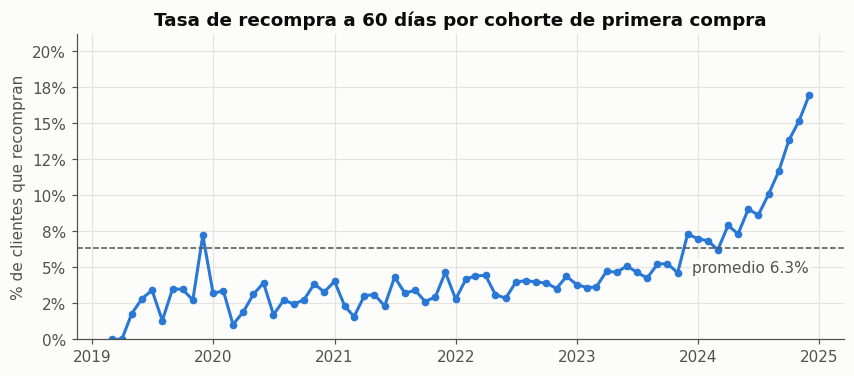

Clientes con ventana completa: 63,538 · recompran a 60 días: 6.3%


In [14]:
ent = base[base.conjunto == "entrenamiento"].copy()
tasa_global = ent[ETIQUETA].mean()
ent["cohorte"] = pd.to_datetime(ent["fecha_primera_compra"]).dt.to_period("M").dt.to_timestamp()
por_cohorte = ent.groupby("cohorte")[ETIQUETA].agg(tasa="mean", clientes="size").reset_index()
por_cohorte = por_cohorte[por_cohorte.clientes >= 30]   # cohortes muy pequeñas son ruido

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(por_cohorte.cohorte, por_cohorte.tasa, color=COLOR["serie1"], lw=2, marker="o", ms=4)
ax.axhline(tasa_global, color=COLOR["texto2"], lw=1, ls="--")
ax.annotate(f"promedio {pct(tasa_global)}", (por_cohorte.cohorte.iloc[-1], tasa_global),
            xytext=(0, -16), textcoords="offset points", ha="right", color=COLOR["texto2"],
            bbox=dict(fc=COLOR["fondo"], ec="none", pad=1))
ax.set_title("Tasa de recompra a 60 días por cohorte de primera compra")
ax.set_ylabel("% de clientes que recompran")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100*v:.0f}%"))
ax.set_ylim(0, max(por_cohorte.tasa.max() * 1.25, tasa_global * 1.5))
guardar_figura(fig, "fig1_tasa_recompra_cohorte")
print(f"Clientes con ventana completa: {len(ent):,} · recompran a 60 días: {pct(tasa_global)}")

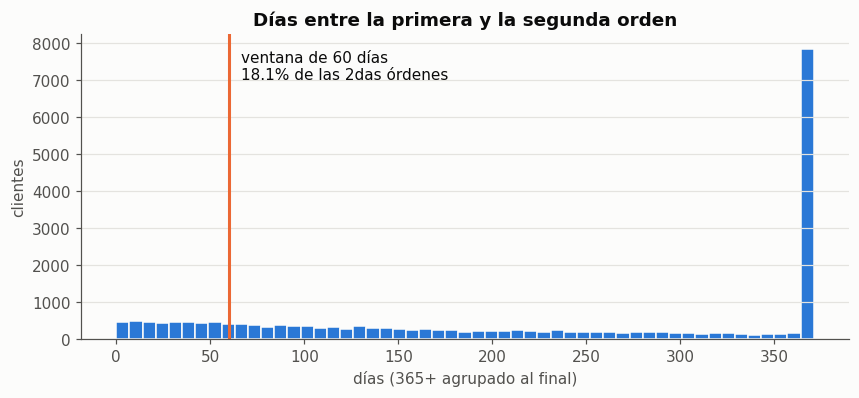

De quienes recompran alguna vez, 18.1% lo hace dentro de 60 días; dentro de la ventana, la mediana es 29 días → momento sugerido para la campaña.


In [15]:
# cuando ocurre la segunda orden (solo clientes que tienen una antes del corte)
dias = ent["aux_dias_a_segunda_orden"].dropna()
dentro = (dias <= CONFIG["VENTANA_DIAS"]).mean()
mediana_60 = dias[dias <= CONFIG["VENTANA_DIAS"]].median()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(dias.clip(upper=365), bins=np.arange(0, 372, 7), color=COLOR["serie1"],
        edgecolor=COLOR["fondo"], linewidth=1)
ax.axvline(CONFIG["VENTANA_DIAS"], color=COLOR["serie2"], lw=2)
ax.annotate(f"ventana de {CONFIG['VENTANA_DIAS']} días\n{pct(dentro)} de las 2das órdenes",
            (CONFIG["VENTANA_DIAS"], ax.get_ylim()[1] * 0.85), xytext=(8, 0),
            textcoords="offset points", color=COLOR["texto"])
ax.set_title("Días entre la primera y la segunda orden")
ax.set_xlabel("días (365+ agrupado al final)")
ax.set_ylabel("clientes")
ax.grid(axis="x", visible=False)
guardar_figura(fig, "fig2_dias_a_segunda_orden")
print(f"De quienes recompran alguna vez, {pct(dentro)} lo hace dentro de {CONFIG['VENTANA_DIAS']} días; "
      f"dentro de la ventana, la mediana es {mediana_60:.0f} días → momento sugerido para la campaña.")

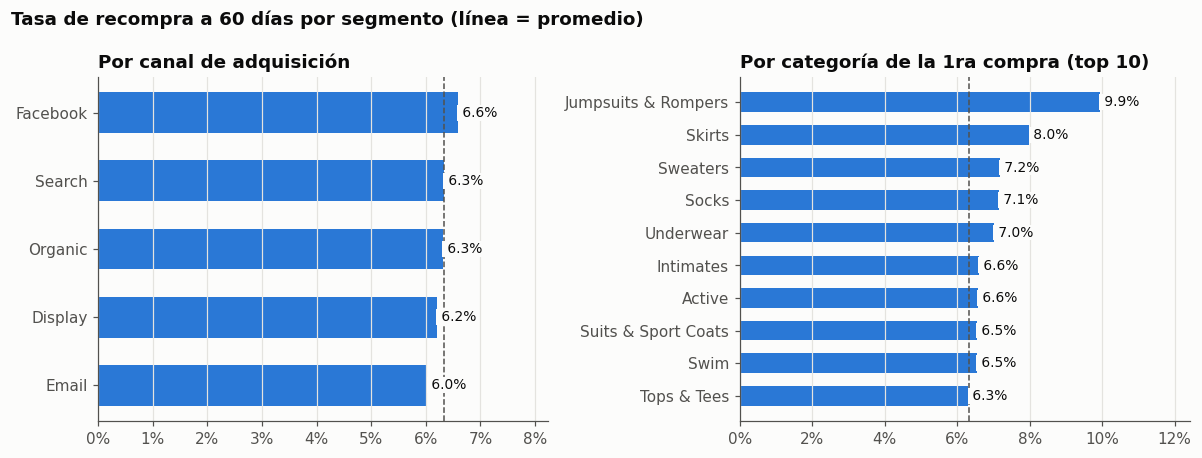

In [16]:
def tasa_por(df, col, min_clientes=100, top=10):
    t = df.groupby(col)[ETIQUETA].agg(tasa="mean", clientes="size")
    return t[t.clientes >= min_clientes].sort_values("tasa").tail(top)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, titulo in [(axes[0], "canal_adquisicion", "Por canal de adquisición"),
                        (axes[1], "categoria_principal", "Por categoría de la 1ra compra (top 10)")]:
    t = tasa_por(ent, col)
    ax.barh(t.index.astype(str), t.tasa, color=COLOR["serie1"], height=0.6)
    ax.axvline(tasa_global, color=COLOR["texto2"], lw=1, ls="--")
    for y, (v, n) in enumerate(zip(t.tasa, t.clientes)):
        ax.text(v, y, f" {pct(v)}", va="center", color=COLOR["texto"], fontsize=9,
                bbox=dict(fc=COLOR["fondo"], ec="none", pad=0.5))
    ax.set_title(titulo, loc="left")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100*v:.0f}%"))
    ax.set_xlim(0, t.tasa.max() * 1.25)
    ax.grid(axis="y", visible=False)
fig.suptitle("Tasa de recompra a 60 días por segmento (línea = promedio)", x=0.01, ha="left",
             fontweight="bold", color=COLOR["texto"])
fig.tight_layout()
guardar_figura(fig, "fig3_recompra_por_segmento")

Lo que me llevo de esta parte:

- Solo el **6,3%** de los clientes vuelve a comprar dentro de 60 días. Es una clase bastante minoritaria, y eso define cómo evalúo en la sección 4.
- La tasa **no es estable en el tiempo**. Entre 2019 y 2023 se mueve entre 2% y 5%, y en 2024 sube hasta ~17% en las últimas cohortes. No sé si es un cambio real del negocio o algo de cómo se generó el dataset (es sintético), pero el modelo tiene que convivir con ese drift.
- De los que vuelven alguna vez, solo el 18% lo hace dentro de los 60 días, con mediana de 29 días. Si se lanza una campaña, conviene hacerlo antes del día 30, no al final de la ventana.
- Por canal casi no hay diferencia (6,0% a 6,6%). Por categoría hay algo más (Jumpsuits & Rompers 9,9%, Skirts 8%), pero son grupos chicos. No esperaba mucha señal por segmento y así fue.

## 4. Modelo

**Split temporal.** Entreno con los clientes más antiguos y evalúo con el 20% más reciente, que es como se usaría en producción. Entre los dos dejo 60 días de separación para que ninguna etiqueta del train se observe dentro del período de test. Con el drift que se vio arriba, un split aleatorio daría números más optimistas de lo que realmente son.

Comparo tres opciones:
1. una **referencia** sin modelo: la tasa histórica del segmento canal × departamento (lo que haría negocio con una tabla dinámica);
2. **regresión logística**, simple e interpretable;
3. **gradient boosting** con `HistGradientBoostingClassifier`, que maneja nulos y categorías sin mucha preparación.

**Métrica.** Con 6% de positivos el accuracy no sirve: decir "nadie recompra" ya da 94%. Uso **PR AUC** como métrica principal y, para la parte de negocio, precision, recall y lift en el **top 20%**, que es la gente que realmente se contactaría.

In [17]:
def split_temporal(df, fraccion_test, gap_dias):
    # train = cohortes antiguas, test = las mas recientes, con gap_dias de separacion
    df = df.sort_values(["primera_compra_ts", "user_id"]).reset_index(drop=True)
    inicio_test = df["primera_compra_ts"].quantile(1 - fraccion_test)
    fin_train = inicio_test - pd.Timedelta(days=gap_dias)
    train = df[df["primera_compra_ts"] < fin_train]
    test = df[df["primera_compra_ts"] >= inicio_test]
    assert train["primera_compra_ts"].max() < test["primera_compra_ts"].min()
    assert set(train.user_id).isdisjoint(test.user_id)
    return train, test


class ReferenciaSegmento(BaseEstimator, ClassifierMixin):
    """Baseline: tasa de recompra del segmento en train, suavizada hacia el promedio (m=50)."""
    def __init__(self, columnas=("canal_adquisicion", "departamento_principal"), m=50):
        self.columnas, self.m = columnas, m

    def _clave(self, X):
        return X[list(self.columnas)].astype(str).agg("|".join, axis=1)

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.global_ = y.mean()
        g = y.groupby(self._clave(X)).agg(["sum", "count"])
        self.tasas_ = ((g["sum"] + self.m * self.global_) / (g["count"] + self.m)).to_dict()
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self._clave(X).map(self.tasas_).fillna(self.global_).to_numpy()
        return np.column_stack([1 - p, p])


SLUG_MODELO = {"Referencia (segmento)": "referencia", "Regresión logística": "logistica",
               "Gradient boosting": "hgb"}


def crear_modelos(semilla):
    imputar_cat = SimpleImputer(strategy="constant", fill_value="desconocido")
    logistica = Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), VARS_NUM),
            ("cat", Pipeline([("imp", imputar_cat),
                              ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30))]), VARS_CAT),
        ])),
        ("modelo", LogisticRegression(max_iter=2000, C=0.5)),
    ])
    boosting = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", Pipeline([("imp", imputar_cat),
                              ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), VARS_CAT),
            ("num", "passthrough", VARS_NUM),     # HistGradientBoosting maneja nulos de forma nativa
        ])),
        ("modelo", HistGradientBoostingClassifier(
            categorical_features=list(range(len(VARS_CAT))), learning_rate=0.05, max_iter=400,
            max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0,
            early_stopping=True, validation_fraction=0.15, random_state=semilla)),
    ])
    return {"Referencia (segmento)": ReferenciaSegmento(),
            "Regresión logística": logistica,
            "Gradient boosting": boosting}


def metricas(y, p, capacidad):
    # ranking (PR AUC, ROC AUC) + metricas en el top `capacidad`, que es donde opera la campaña
    y = np.asarray(y).astype(int)
    k = max(1, math.ceil(capacidad * len(y)))
    top = np.argsort(-p, kind="stable")[:k]
    tp = y[top].sum()
    prec, rec = tp / k, tp / max(1, y.sum())
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "prevalencia": y.mean(), f"precision_top{int(capacidad*100)}": prec,
            f"recall_top{int(capacidad*100)}": rec,
            f"f1_top{int(capacidad*100)}": 2 * prec * rec / max(1e-9, prec + rec),
            f"lift_top{int(capacidad*100)}": prec / y.mean()}


def ic_bootstrap_pr_auc(y, p, n=300, semilla=42):
    # IC 90% de la PR AUC remuestreando el test, para ver si dos modelos de verdad se diferencian
    rng, y = np.random.default_rng(semilla), np.asarray(y).astype(int)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() > 0:
            vals.append(average_precision_score(y[i], p[i]))
    return np.percentile(vals, [5, 95])


def entrenar_y_evaluar(ent, cfg):
    train, test = split_temporal(ent, cfg["FRACCION_TEST"], cfg["VENTANA_DIAS"])
    print(f"Train: {len(train):,} clientes ({train.fecha_primera_compra.min()} → {train.fecha_primera_compra.max()}) · "
          f"tasa {pct(train[ETIQUETA].mean())}")
    print(f"Test:  {len(test):,} clientes ({test.fecha_primera_compra.min()} → {test.fecha_primera_compra.max()}) · "
          f"tasa {pct(test[ETIQUETA].mean())}")
    modelos, filas, probs = crear_modelos(cfg["SEMILLA"]), [], {}
    for nombre, m in modelos.items():
        m.fit(train[FEATURES], train[ETIQUETA].astype(int))
        p = m.predict_proba(test[FEATURES])[:, 1]
        probs[nombre] = p
        lo, hi = ic_bootstrap_pr_auc(test[ETIQUETA], p, semilla=cfg["SEMILLA"])
        filas.append({"modelo": nombre, **metricas(test[ETIQUETA], p, cfg["CAPACIDAD_CAMPANA"]),
                      "pr_auc_ic90": f"[{lo:.3f}, {hi:.3f}]"})
    tabla = pd.DataFrame(filas).set_index("modelo")
    ganador = tabla["pr_auc"].idxmax()
    return {"train": train, "test": test, "modelos": modelos, "probs": probs,
            "tabla": tabla, "ganador": ganador}

In [18]:
res = entrenar_y_evaluar(ent, CONFIG)
display(res["tabla"].round(3))
print("Modelo seleccionado por PR AUC en test:", res["ganador"])

Train: 47,119 clientes (2019-01-22 → 2024-05-08) · tasa 4.4%
Test:  12,708 clientes (2024-07-07 → 2024-12-16) · tasa 12.8%


,pr_auc,roc_auc,prevalencia,precision_top20,recall_top20,f1_top20,lift_top20,pr_auc_ic90
modelo,,,,,,,,
Referencia (segmento),0.129,0.507,0.128,0.110,0.172,0.134,0.860,"[0.123, 0.136]"
Regresión logística,0.219,0.702,0.128,0.238,0.373,0.291,1.866,"[0.206, 0.232]"
Gradient boosting,0.220,0.695,0.128,0.231,0.362,0.282,1.807,"[0.207, 0.233]"


Modelo seleccionado por PR AUC en test: Gradient boosting


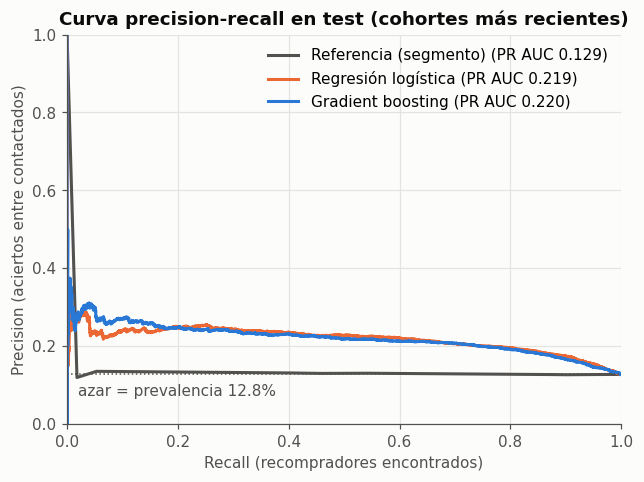

In [19]:
y_test = res["test"][ETIQUETA].astype(int).to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 4.6))
colores = [COLOR["texto2"], COLOR["serie2"], COLOR["serie1"]]
for (nombre, p), c in zip(res["probs"].items(), colores):
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, color=c, lw=2, label=f"{nombre} (PR AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), color=COLOR["texto2"], lw=1, ls=":")
ax.annotate(f"azar = prevalencia {pct(y_test.mean())}", (0.02, y_test.mean()), xytext=(0, -14),
            textcoords="offset points", color=COLOR["texto2"])
ax.set_xlabel("Recall (recompradores encontrados)")
ax.set_ylabel("Precision (aciertos entre contactados)")
ax.set_title("Curva precision-recall en test (cohortes más recientes)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="upper right")
guardar_figura(fig, "fig4_curva_pr")

,clientes,recompras,prob_media,tasa_real,lift,captura_acumulada
decil,,,,,,
1,1271,314,0.083,0.247,1.937,0.194
2,1271,272,0.062,0.214,1.678,0.362
3,1271,244,0.055,0.192,1.505,0.512
4,1270,238,0.051,0.187,1.469,0.659
5,1271,185,0.046,0.146,1.141,0.773
6,1271,129,0.039,0.101,0.796,0.853
7,1270,84,0.035,0.066,0.519,0.904
8,1271,64,0.032,0.050,0.395,0.944
9,1271,56,0.028,0.044,0.345,0.978


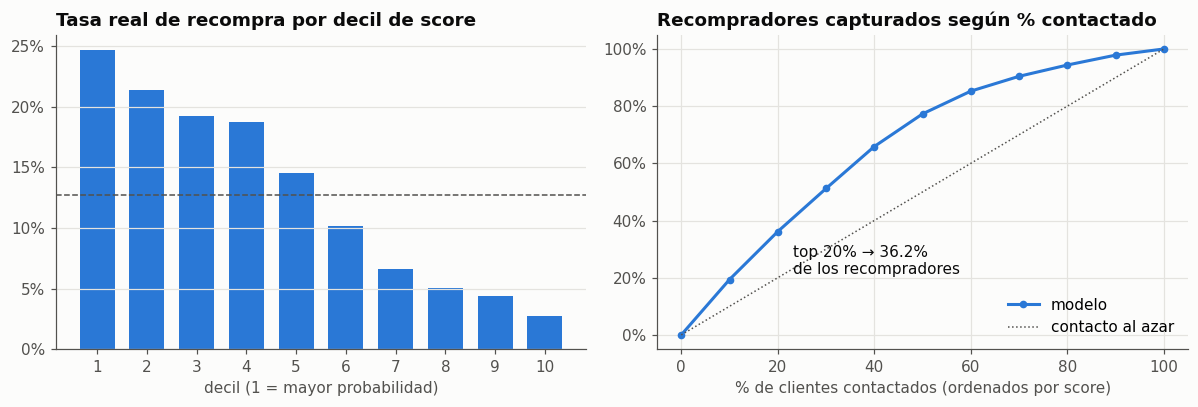

In [20]:
def tabla_deciles(y, p):
    """Decil 1 = clientes con mayor probabilidad."""
    d = pd.DataFrame({"y": np.asarray(y).astype(int), "p": p})
    d["decil"] = 10 - pd.qcut(d.p.rank(method="first"), 10, labels=False)
    t = d.groupby("decil").agg(clientes=("y", "size"), recompras=("y", "sum"), prob_media=("p", "mean"))
    t["tasa_real"] = t.recompras / t.clientes
    t["lift"] = t.tasa_real / d.y.mean()
    t["captura_acumulada"] = t.recompras.cumsum() / d.y.sum()
    return t

deciles = tabla_deciles(y_test, res["probs"][res["ganador"]])
display(deciles.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(deciles.index, deciles.tasa_real, color=COLOR["serie1"], width=0.7)
axes[0].axhline(y_test.mean(), color=COLOR["texto2"], lw=1, ls="--")
axes[0].set_title("Tasa real de recompra por decil de score", loc="left")
axes[0].set_xlabel("decil (1 = mayor probabilidad)"); axes[0].set_xticks(deciles.index)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100*v:.0f}%"))
axes[0].grid(axis="x", visible=False)
axes[1].plot(np.r_[0, deciles.index * 10], np.r_[0, deciles.captura_acumulada], color=COLOR["serie1"],
             lw=2, marker="o", ms=4, label="modelo")
axes[1].plot([0, 100], [0, 1], color=COLOR["texto2"], lw=1, ls=":", label="contacto al azar")
k = int(CONFIG["CAPACIDAD_CAMPANA"] * 100)
cap_k = deciles.captura_acumulada.iloc[k // 10 - 1]
axes[1].annotate(f"top {k}% → {pct(cap_k)}\nde los recompradores", (k, cap_k), xytext=(10, -28),
                 textcoords="offset points", color=COLOR["texto"])
axes[1].set_title("Recompradores capturados según % contactado", loc="left")
axes[1].set_xlabel("% de clientes contactados (ordenados por score)")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100*v:.0f}%"))
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
guardar_figura(fig, "fig5_lift_deciles")

In [21]:
# importancia por permutacion en test: cuanto cae la PR AUC si desordeno cada variable
imp = permutation_importance(res["modelos"][res["ganador"]], res["test"][FEATURES], y_test,
                             scoring="average_precision", n_repeats=5, random_state=CONFIG["SEMILLA"])
importancias = (pd.DataFrame({"variable": FEATURES, "caida_pr_auc": imp.importances_mean})
                .sort_values("caida_pr_auc", ascending=False).reset_index(drop=True))
importancias.head(10).round(4)

,variable,caida_pr_auc
0,dias_registro_a_compra,0.0935
1,mes_primera_compra,0.0072
2,categoria_principal,0.0037
3,n_eventos_previos,0.0018
4,precio_max_item,0.0008
5,margen_bruto,0.0007
6,dia_semana_primera_compra,0.0006
7,n_eventos_carrito,0.0002
8,canal_adquisicion,0.0001
9,n_categorias,0.0001


Me llamó la atención que `dias_registro_a_compra` pese mucho más que todo lo demás. Sospecho que funciona como un reloj: con la tasa subiendo en 2024, cualquier variable relacionada con *cuándo* fue la compra va a parecer predictiva.

No es fuga (la variable se conoce el día de la compra), pero sí es lo primero que revisaría con mas tiempo: ver la tasa por año y probar entrenar solo con el último año de datos.

**Cómo leo los resultados**

Logística y boosting quedan prácticamente empatados (PR AUC 0,219 vs 0,220, con intervalos que se solapan casi completos). El código elige el de mayor PR AUC, que es el boosting, pero la logística sería igual de válida y más fácil de explicar. La referencia por segmento queda por debajo del azar, y tiene sentido: las tasas por segmento del pasado no sirven cuando la tasa general se triplica.

En términos de negocio: contactando al 20% con mayor score se encuentra al 36% de los que van a recomprar (al azar sería 20%), y el primer decil recompra casi el doble que el promedio. No es un modelo espectacular, pero ordena bien.

Lo que sé que falta:
- El modelo dice quién va a recomprar, no quién recompra *gracias* a la campaña. Para eso hace falta un grupo de control y después un modelo de uplift.
- Datos sintéticos y un drift fuerte en 2024. En producción haría backtesting con varias fechas de corte, no con una sola.
- No tengo costos de campaña ni margen por cliente; el 20% de capacidad es un supuesto mío.
- Si las probabilidades se van a usar como tal (y no solo para ordenar), habría que calibrarlas.

## 5. Predicciones
Reentreno el modelo elegido con todos los clientes etiquetados y puntúo a los que hicieron su primera compra en los 60 días anteriores al corte. A los que ya recompraron en ese tiempo los marco para no contactarlos; no tiene sentido gastar en ellos.

In [22]:
def entrenar_final(ent, nombre_modelo, cfg):
    modelo = crear_modelos(cfg["SEMILLA"])[nombre_modelo]
    modelo.fit(ent[FEATURES], ent[ETIQUETA].astype(int))
    return modelo


def predecir(modelo, df_scoring, fecha_corte, cfg, version):
    p = modelo.predict_proba(df_scoring[FEATURES])[:, 1]
    out = df_scoring[["user_id", "fecha_primera_compra", "aux_dias_observados",
                      "aux_ya_recompro_al_corte"]].copy()
    out = out.rename(columns={"aux_dias_observados": "dias_desde_primera_compra",
                              "aux_ya_recompro_al_corte": "ya_recompro"})
    out["probabilidad_recompra"] = p.round(5)
    out["decil"] = (10 - pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)).to_numpy() if len(p) >= 10 else 1
    corte_prioridad = np.quantile(p, 1 - cfg["CAPACIDAD_CAMPANA"]) if len(p) else 1
    out["accion"] = np.select(
        [out.ya_recompro == 1, p >= corte_prioridad],
        ["Ya recompró: no contactar", "Prioridad alta: contactar"], "Sin contacto / canal de bajo costo")
    out["fecha_corte"] = fecha_corte
    out["modelo_version"] = version
    out["fecha_ejecucion"] = pd.Timestamp.now(tz="UTC")
    return out.sort_values("probabilidad_recompra", ascending=False).reset_index(drop=True)


def validar_predicciones(pred, df_scoring):
    errores = []
    if not pred.user_id.is_unique: errores.append("user_id duplicado en predicciones")
    if len(pred) != len(df_scoring): errores.append("no se puntuaron todos los clientes")
    if not pred.probabilidad_recompra.between(0, 1).all(): errores.append("probabilidad fuera de [0, 1]")
    if errores:
        raise ErrorCalidadDatos(" | ".join(errores))


def guardar_resultados(modelo, pred, metr, cfg, fecha_corte, version):
    # archivos con nombre por fecha de corte + particion por fecha en BQ: volver a correr pisa, no duplica
    sufijo = fecha_corte.strftime("%Y%m%d")
    joblib.dump({"modelo": modelo, "features": FEATURES, "version": version,
                 "fecha_corte": fecha_corte, "config": cfg, "metricas_test": metr},
                DIR_MODELOS / "modelo_recompra_60d.joblib")
    pred.to_csv(DIR_SALIDAS / f"predicciones_{sufijo}.csv", index=False)
    pred[["user_id", "probabilidad_recompra", "decil", "accion"]].head(500).to_csv(
        DIR_SALIDAS / "predicciones_muestra.csv", index=False)
    (DIR_SALIDAS / "metricas.json").write_text(json.dumps(metr, indent=2, default=str), encoding="utf-8")
    if cfg["GUARDAR_EN_BQ"]:
        tabla = nombre_tabla(cfg, "predicciones_recompra_60d", destino=True)
        reemplazar_particion(pred, tabla, fecha_corte)
        n = contar_filas(tabla, fecha_corte)
        assert n == len(pred), f"BigQuery tiene {n} filas para {fecha_corte}, se esperaban {len(pred)}"
        print(f"Predicciones en {tabla} (partición {fecha_corte}): {n:,} filas")

In [23]:
scoring = base[base.conjunto == "scoring"]
VERSION = f'{SLUG_MODELO[res["ganador"]]}_{FECHA_CORTE:%Y%m%d}'
modelo_final = entrenar_final(ent, res["ganador"], CONFIG)
pred = predecir(modelo_final, scoring, FECHA_CORTE, CONFIG, VERSION)
validar_predicciones(pred, scoring)
metr = {"fecha_corte": FECHA_CORTE, "modelo": res["ganador"], "version": VERSION,
        "tasa_recompra_entrenamiento": tasa_global,
        "test": res["tabla"].drop(columns="pr_auc_ic90").round(4).to_dict(orient="index"),
        "pr_auc_ic90": res["tabla"]["pr_auc_ic90"].to_dict(),
        "captura_top_capacidad": float(cap_k), "clientes_scoring": len(pred)}
guardar_resultados(modelo_final, pred, metr, CONFIG, FECHA_CORTE, VERSION)
display(pred.accion.value_counts())
pred.head(10)

  BigQuery: 0.000 GB procesados
Predicciones en bussiness-case-tyc.tais_arrunategui.predicciones_recompra_60d (partición 2025-02-15): 8,489 filas


,count
accion,
Sin contacto / canal de bajo costo,5716
Ya recompró: no contactar,1682
Prioridad alta: contactar,1091


,user_id,fecha_primera_compra,dias_desde_primera_compra,ya_recompro,probabilidad_recompra,decil,accion,fecha_corte,modelo_version,fecha_ejecucion
0,49151.0,2024-12-25,51.0,0.0,0.34363,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
1,99620.0,2024-12-17,59.0,1.0,0.33899,1,Ya recompró: no contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
2,56889.0,2024-12-24,52.0,1.0,0.33455,1,Ya recompró: no contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
3,5418.0,2024-12-28,48.0,0.0,0.33378,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
4,73587.0,2024-12-27,49.0,0.0,0.32456,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
5,87974.0,2024-12-30,46.0,0.0,0.31358,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
6,51541.0,2024-12-24,52.0,0.0,0.30994,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
7,62598.0,2024-12-27,49.0,0.0,0.30953,1,Prioridad alta: contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
8,10515.0,2024-12-29,47.0,1.0,0.30217,1,Ya recompró: no contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00
9,2146.0,2024-12-31,45.0,1.0,0.29823,1,Ya recompró: no contactar,2025-02-15,hgb_20250215,2026-10-20 05:37:33.431360+00:00


## 6. Todo junto
`ejecutar_pipeline` hace el recorrido completo con lo que haya en `CONFIG`: tabla base, validaciones, entrenamiento, predicciones y guardado. Es lo que correría un scheduler en producción (ver `docs/arquitectura.md`).

Lo corro una segunda vez con la misma fecha de corte y reviso que no se dupliquen filas.

In [24]:
def ejecutar_pipeline(cfg):
    fecha_corte = resolver_fecha_corte(cfg)
    print(f"▶ Fecha de corte {fecha_corte} · ventana {cfg['VENTANA_DIAS']} días")
    df = construir_tabla_base(cfg, fecha_corte)
    validar_tabla_base(df, cfg, fecha_corte)
    etiquetados = df[df.conjunto == "entrenamiento"]
    r = entrenar_y_evaluar(etiquetados, cfg)
    version = f'{SLUG_MODELO[r["ganador"]]}_{fecha_corte:%Y%m%d}'
    modelo = entrenar_final(etiquetados, r["ganador"], cfg)
    scoring = df[df.conjunto == "scoring"]
    pred = predecir(modelo, scoring, fecha_corte, cfg, version)
    validar_predicciones(pred, scoring)
    metr = {"fecha_corte": fecha_corte, "modelo": r["ganador"], "version": version,
            "tasa_recompra_entrenamiento": etiquetados[ETIQUETA].mean(),
            "test": r["tabla"].drop(columns="pr_auc_ic90").round(4).to_dict(orient="index"),
            "pr_auc_ic90": r["tabla"]["pr_auc_ic90"].to_dict(),
            "captura_top_capacidad": float(tabla_deciles(r["test"][ETIQUETA], r["probs"][r["ganador"]])
                                           .captura_acumulada.iloc[int(cfg["CAPACIDAD_CAMPANA"] * 10) - 1]),
            "clientes_scoring": len(pred)}
    guardar_resultados(modelo, pred, metr, cfg, fecha_corte, version)
    print(f"✔ Pipeline completo: {len(pred):,} clientes puntuados con {r['ganador']}")
    return pred, metr

pred_2, metr_2 = ejecutar_pipeline(CONFIG)

# misma fecha de corte -> mismos clientes y sin filas duplicadas
assert len(pred_2) == len(pred) and set(pred_2.user_id) == set(pred.user_id)
csv = pd.read_csv(DIR_SALIDAS / f"predicciones_{FECHA_CORTE:%Y%m%d}.csv")
assert csv.user_id.is_unique and len(csv) == len(pred)
print("✔ Re-ejecución idempotente: no se duplicaron resultados")

▶ Fecha de corte 2025-02-15 · ventana 60 días
  BigQuery: 0.161 GB procesados
  BigQuery: 0.007 GB procesados


,severidad,control,afectados,estado
0,advertencia,compra anterior al registro del usuario,0,OK
1,advertencia,"edad nula o fuera de rango [10, 100]",0,OK
2,advertencia,primera orden sin ítems (canasta nula),0,OK
3,critico,entrenamiento sin ventana completa observada,0,OK
4,critico,"etiqueta fuera de {0,1}",0,OK
5,critico,etiqueta nula en entrenamiento,0,OK
6,critico,etiqueta presente en scoring (debe ser nula),0,OK
7,critico,grano: 1 fila por cliente,0,OK
8,critico,grano: 1 primera orden por cliente,0,OK
9,critico,primera compra en o después del corte,0,OK


Tabla base válida: 72,027 clientes (63,538 entrenamiento · 8,489 scoring)
Proporción de nulos por variable (se imputan en el pipeline): {'dias_primer_evento_a_compra': 0.0}
Train: 47,119 clientes (2019-01-22 → 2024-05-08) · tasa 4.4%
Test:  12,708 clientes (2024-07-07 → 2024-12-16) · tasa 12.8%
  BigQuery: 0.000 GB procesados
  BigQuery: 0.000 GB procesados
Predicciones en bussiness-case-tyc.tais_arrunategui.predicciones_recompra_60d (partición 2025-02-15): 8,489 filas
✔ Pipeline completo: 8,489 clientes puntuados con Gradient boosting
✔ Re-ejecución idempotente: no se duplicaron resultados


## Notas sobre escala
Con este volumen la tabla base procesa unos 160 MB en BigQuery, así que no hizo falta optimizar mucho. Lo que ya está aplicado: leer solo las columnas necesarias, filtrar ítems y eventos antes de agregar, y agregar antes de unir (los joins que multiplican filas son el problema típico en este tipo de tabla).

Si el volumen creciera:
- particionaría `orders`, `order_items` y `events` por fecha y haría clustering por `user_id`;
- armaría la tabla base de forma incremental: cada mes entran solo las cohortes cuya ventana se cerró, con un `MERGE`.

En Snowflake el SQL casi no cambia (`QUALIFY` existe, `COUNTIF` pasa a `COUNT_IF`, `TIMESTAMP_ADD` a `DATEADD`). Usaría clustering keys por fecha, un warehouse chico solo para este proceso con auto-suspend, y Streams + Tasks para la carga incremental. Más detalle en `docs/arquitectura.md`.